# Module 6 — Fishbone (Ishikawa) Diagram

Part of the Root-Cause Analysis Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

- The 5 Whys follows one chain. A fishbone does the opposite: it lists *every* candidate cause first, sorted into categories, so none is skipped.
- Every branch on a fishbone is a hypothesis to test, not a finding. The diagram is only finished once each branch has been tested and scored.
- In DMAIC (Define, Measure, Analyze, Improve, Control), it is an **Analyze** tool: it gives breadth before depth.

**What this module produces:**
1. A fishbone for a real churn question: six bones, 22 candidate causes plus checks of the churn label itself.
2. Every branch tested, and the diagram scored by the results.
3. A correction for testing many branches at once, and an honest conclusion.

## From the curriculum

> ## <u>Module 6 — Fishbone (Ishikawa) Diagram</u>
>
> **DMAIC phase:** Analyze (listing candidate causes with breadth).
>
> **Concepts**
> - The diagram (Kaoru Ishikawa, popularised in the 1960s): the problem as the
>   head, cause categories as bones, causes and sub-causes as branches
> - Category sets: the manufacturing "Ms" (Manpower, Machine, Material, Method,
>   Measurement, often extended with Mother Nature and others), and a
>   data-and-product adaptation (customer, product use, support, commercial,
>   time, measurement)
> - The fishbone as a hypothesis inventory: every branch is something to test,
>   not a finding
> - Scoring each branch by the evidence once tested, and correcting for testing
>   many branches at once
>
> **Why it matters**
> A fishbone protects against the most common investigation error: testing
> only the first cause anyone thought of.
>
> **Worked example**
> The E08 churn exercise (a take-home exercise with artificial data: 500
> accounts, 22.0% flagged as churned), recomputed (reuse). 22 candidate causes
> on five bones, each tested, plus checks of the churn label on a sixth:
> - No customer, product, support or commercial branch clears its significance
>   bar once the number of tests is accounted for.
> - The measurement bone holds the real finding: the tables disagree on who
>   churned at all.
>
> An honest case where the fishbone ends with "no validated driver", and the
> measurement bone explains why.
>
> **Resources**
> - [Ishikawa diagram](https://en.wikipedia.org/wiki/Ishikawa_diagram)
>   (Wikipedia, ~10 min, verified): the diagram, its origin, and the category
>   sets used in manufacturing, marketing and services.
>
> **Exercise type:** decide whether the lowest p-value is a driver, given how
> many branches were tested. Fully worked.
>
> **Interview angle:** "How do you make sure you haven't missed a cause?"

## Lesson

### The diagram

- **The head:** the problem, stated as a fact ("22.0% of accounts churned").
- **The bones:** categories of cause, one per main branch, e.g. "customer", "product use", "support".
- **The branches:** specific candidate causes on each bone, e.g. on the "support" bone: "support response is slow".

### Categories

- **Manufacturing:** the "Ms": Manpower, Machine, Material, Method, Measurement, often extended with Mother Nature (environment) and others.
- **Data and product problems (this module):** customer (who they are), product use, support, commercial (price, plan, billing), time, and measurement (is the data itself right?).

The categories are a prompt, not a rule. Their job is to make the team look in places it would otherwise skip.

### From inventory to answer

1. List the candidate causes on each bone.
2. Name the data that would test each one.
3. Test each, and score it. A test gives a **p-value**: the chance of a difference this large if the branch had no effect. Scores: *supported* (p below the corrected bar, step 4), *watch item* (p below 0.10, a chosen bar for "worth a second look", not a finding), or *not supported*.
4. **Correct for testing many at once.** With 20 tests (a chosen example) at the usual bar of p < 0.05, about 20 × 0.05 = 1 "significant" result is expected by chance alone. Divide the bar by the number of tests (the Bonferroni correction).

A fishbone can end with "no branch is supported". That is a real result, and it often points at the measurement bone.

## Worked example: why do 22.0% of accounts churn?

**Data choice: reuse.** The E08 churn exercise tested a long list of candidate causes and found none that held, which is the honest end a fishbone must allow. Re-running it as a fishbone shows the method, including the bone that explained the "no cause found" result.

**Where this was already done, unnamed:** the user's E08 exercise (`AI Analyst Workspace/Reports/E08_Summary.md`, a local file).

**The data:** a take-home exercise with artificial data for a software company, in five tables: accounts (one row per customer account, with a churn flag), subscriptions, feature usage, support tickets, and churn events. The source files are not redistributed here (take-home exercise data); `python data/get_data.py` copies them from the local E08 folder and checks them.

**The question as asked:** leadership asked why retention has been getting worse. The original E08 analysis found it was not getting worse: churn is a steady level, once accounts are compared at equal age. So the question here is the steady level itself: *why do 22.0% of accounts churn?*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import common
from common import show, BLUE, ORANGE, AQUA, GREY

t = common.load_e08()
A, S, U, T, C = (t[k] for k in ["accounts", "subscriptions", "feature_usage", "support_tickets", "churn_events"])
print("What is in the data?")
for k, v in t.items():
    print(f"  {k} = {len(v):,} rows")
print(f"\nThe head of the fishbone: accounts flagged churned = {A['churn_flag'].sum()} of {len(A)} = {A['churn_flag'].mean():.1%}")

What is in the data?
  accounts = 500 rows
  subscriptions = 5,000 rows
  feature_usage = 25,000 rows
  support_tickets = 2,000 rows
  churn_events = 600 rows

The head of the fishbone: accounts flagged churned = 110 of 500 = 22.0%


**Observation:** 110 of the 500 accounts are flagged churned: 22.0%. That is the head of the fishbone.

### Part 1 — The bones and their branches

Six bones, and on each one the candidate causes that the data can test. This is the inventory: nothing on it is a finding yet.

| bone | candidate causes (branches) | compared | test |
|---|---|---|---|
| **customer** | industry, country, referral source, plan tier, number of seats, trial account | churn rate by group | chi-square |
| **product use** | feature uses, usage hours, errors, share of beta-feature use | churned vs. not churned accounts | Mann-Whitney |
| **support** | number of tickets, resolution time, first response time, satisfaction, escalations | churned vs. not churned accounts | Mann-Whitney |
| **commercial** | number of subscriptions, monthly revenue, upgrades, downgrades, auto-renew, annual billing | churned vs. not churned accounts | Mann-Whitney |
| **time** | account age (days since signup) | churned vs. not churned accounts | Mann-Whitney |
| **measurement** | is the churn flag itself right? | do the tables agree on who churned? | direct counts |

The two tests, in one line each: a **chi-square test** asks whether the churn rate differs between groups more than chance would explain; a **Mann-Whitney test** asks whether churned accounts tend to have higher (or lower) values than the others. Both give a p-value: the chance of a difference this large if the branch had no effect.

### Part 2 — Test the customer bone

In [2]:
A["seats band"] = pd.cut(A["seats"], [0, 5, 10, 25, 50, 10**6], labels=["1-5", "6-10", "11-25", "26-50", "51+"])
rows = []
for col, label in [("industry", "industry"), ("country", "country"), ("referral_source", "referral source"),
                   ("plan_tier", "plan tier"), ("seats band", "number of seats"), ("is_trial", "trial account")]:
    rate = A.groupby(col, observed=True)["churn_flag"].mean(); size = A.groupby(col, observed=True).size()
    p = stats.chi2_contingency(pd.crosstab(A[col], A["churn_flag"]))[1]
    rows.append({"bone": "customer", "branch": label, "p-value": p,
                 "difference (highest − lowest)": f"{rate.max() - rate.min():.1%}",
                 "lowest vs. highest churn rate": f"{rate.min():.1%} ({rate.idxmin()}, n = {size[rate.idxmin()]}) vs. {rate.max():.1%} ({rate.idxmax()}, n = {size[rate.idxmax()]})"})
customer = pd.DataFrame(rows)
print("Customer bone: does the churn rate differ between groups? (seat bands chosen: 1-5, 6-10, 11-25, 26-50, 51+)\n")
show(customer.assign(**{"p-value": customer["p-value"].map("{:.3f}".format)}))

Customer bone: does the churn rate differ between groups? (seat bands chosen: 1-5, 6-10, 11-25, 26-50, 51+)

bone      branch           p-value  difference (highest − lowest)  lowest vs. highest churn rate
customer  industry           0.066                          15.0%  16.0% (Cybersecurity, n = 100) vs. 31.0% (DevTools, n = 113)
customer  country            0.659                          19.5%  12.5% (AU, n = 32) vs. 32.0% (DE, n = 25)
customer  referral source    0.079                          15.6%  14.6% (partner, n = 89) vs. 30.2% (event, n = 96)
customer  plan tier          0.999                           0.2%  21.9% (Pro, n = 178) vs. 22.1% (Enterprise, n = 154)
customer  number of seats    0.622                           9.0%  20.1% (11-25, n = 159) vs. 29.2% (6-10, n = 72)
customer  trial account      0.388                           4.7%  21.1% (False, n = 403) vs. 25.8% (True, n = 97)


**Observation:** no customer branch reaches p < 0.05. The lowest are industry (p = 0.066) and referral source (p = 0.079). Some spreads look large (country: 12.5% to 32.0%), but they come from small groups (32 and 25 accounts), where a few churned accounts swing the rate a lot. That is why the p-value stays high.

### Part 3 — Test the product, support, commercial and time bones

Each account gets one number per branch, built from that bone's own table: usage rows for product use, tickets for support, subscriptions for commercial. The description column says how each number is built. Then churned accounts are compared with the others. Account age = days from signup to the latest date in the data. The support branches compare only accounts with at least one ticket (printed below):

In [3]:
use = U.merge(S[["subscription_id", "account_id"]], on="subscription_id").groupby("account_id")
tk, sb = T.groupby("account_id"), S.assign(annual=S["billing_frequency"].eq("annual")).groupby("account_id")
snapshot = max(S["start_date"].max(), A["signup_date"].max())
f = pd.DataFrame(index=A["account_id"])
spec = [("product use", "feature uses", use["usage_count"].sum()), ("product use", "usage hours", use["usage_duration_secs"].sum() / 3600),
        ("product use", "errors", use["error_count"].sum()), ("product use", "beta-feature share", use["is_beta_feature"].mean()),
        ("support", "tickets", tk.size()), ("support", "resolution hours", tk["resolution_time_hours"].mean()),
        ("support", "first response minutes", tk["first_response_time_minutes"].mean()),
        ("support", "satisfaction", tk["satisfaction_score"].mean()), ("support", "escalation share", tk["escalation_flag"].mean()),
        ("commercial", "subscriptions", sb.size()), ("commercial", "monthly revenue", sb["mrr_amount"].sum()),
        ("commercial", "upgrades", sb["upgrade_flag"].sum()), ("commercial", "downgrades", sb["downgrade_flag"].sum()),
        ("commercial", "auto-renew share", sb["auto_renew_flag"].mean()), ("commercial", "annual billing share", sb["annual"].mean()),
        ("time", "account age (days)", (snapshot - A.set_index("account_id")["signup_date"]).dt.days)]
DESC = {'feature uses': 'times features were used (sum)', 'usage hours': 'time spent in features (sum)', 'errors': 'errors hit while using features (sum)', 'beta-feature share': 'share of usage rows on beta features', 'tickets': 'support tickets filed', 'resolution hours': 'hours from ticket opened to closed (average)', 'first response minutes': "minutes until support's first reply (average)", 'satisfaction': 'ticket satisfaction score (average)', 'escalation share': 'share of tickets escalated', 'subscriptions': 'subscription records on the account', 'monthly revenue': 'monthly revenue, summed over subscriptions', 'upgrades': 'subscriptions marked as an upgrade', 'downgrades': 'subscriptions marked as a downgrade', 'auto-renew share': 'share of subscriptions set to auto-renew', 'annual billing share': 'share of subscriptions billed yearly', 'account age (days)': 'days from signup to the latest date'}
churned = A.set_index("account_id")["churn_flag"]
rows = []
for bone, label, values in spec:
    v = values.reindex(A["account_id"])
    a, b = v[churned.to_numpy()].dropna(), v[~churned.to_numpy()].dropna()
    fmt = (lambda x: f"{x:.1%}") if "share" in label else (lambda x: f"{x:,.1f}")
    rows.append({"bone": bone, "branch": label, "description": DESC[label], "p-value": stats.mannwhitneyu(a, b).pvalue,
                 "median: churned vs. not": f"{fmt(a.median())} vs. {fmt(b.median())}"})
numeric = pd.DataFrame(rows)
print(f"latest date in the data = {snapshot:%Y-%m-%d}")
print(f"accounts with at least one ticket = {T['account_id'].nunique()} of {len(A)}\n")
print("Churned vs. not churned accounts, one row per branch:\n")
show(numeric.assign(**{"p-value": numeric["p-value"].map("{:.3f}".format)}))

latest date in the data = 2024-12-31
accounts with at least one ticket = 492 of 500

Churned vs. not churned accounts, one row per branch:

bone         branch                  description                                    p-value  median: churned vs. not
product use  feature uses            times features were used (sum)                   0.206  527.5 vs. 491.0
product use  usage hours             time spent in features (sum)                     0.203  43.6 vs. 41.4
product use  errors                  errors hit while using features (sum)            0.795  28.5 vs. 27.0
product use  beta-feature share      share of usage rows on beta features             0.867  10.0% vs. 10.0%
support      tickets                 support tickets filed                            0.353  4.0 vs. 4.0
support      resolution hours        hours from ticket opened to closed (average)     0.717  35.5 vs. 36.0
support      first response minutes  minutes until support's first reply (average)    0.103  83.6 v

**Observation:** no branch reaches p < 0.05. The closest is account age (p = 0.059): churned accounts are older (median 379.5 days against 301.0). The rest range from p = 0.103 to 0.907.

**Hypothesis:** older accounts are flagged more often simply because they have had more time to churn. The original E08 analysis compared accounts at equal age and the gap disappeared, which fits this explanation. It is not re-tested here.

### Part 4 — Test the measurement bone

There are three ways to say an account churned in this data: the account's own churn flag, a churned subscription, and a row in the churn events table. If the churn flag is right, the three should mostly agree. Two more checks follow: a churned account should have no open subscription left, and usage cannot happen before its subscription starts:

In [4]:
any_sub = A["account_id"].map(S.groupby("account_id")["churn_flag"].any()).fillna(False)
in_events = A["account_id"].isin(C["account_id"])
flag = A["churn_flag"]
print("How many accounts count as churned, by each signal?")
print(f"  {flag.mean():.1%} of accounts have the churn flag set")
print(f"  {any_sub.mean():.1%} of accounts have at least one churned subscription")
print(f"  {in_events.mean():.1%} of accounts appear in the churn events table")
print()
print("Do the signals agree?")
print(f"  {in_events[flag].mean():.1%} of flagged accounts appear in the churn events table")
print(f"  {in_events[~flag].mean():.1%} of unflagged accounts appear in the churn events table")
print()
open_subs = S[S["end_date"].isna()]["account_id"]
u = U.merge(S[["subscription_id", "start_date"]], on="subscription_id")
print("Two more checks:")
print(f"  {A.loc[flag, 'account_id'].isin(open_subs).mean():.1%} of flagged and {A.loc[~flag, 'account_id'].isin(open_subs).mean():.1%} of unflagged accounts still have an open subscription")
print(f"  {(u['usage_date'] < u['start_date']).mean():.1%} of usage rows are dated before their own subscription started")

How many accounts count as churned, by each signal?
  22.0% of accounts have the churn flag set
  62.4% of accounts have at least one churned subscription
  70.4% of accounts appear in the churn events table

Do the signals agree?
  68.2% of flagged accounts appear in the churn events table
  71.0% of unflagged accounts appear in the churn events table

Two more checks:
  100.0% of flagged and 100.0% of unflagged accounts still have an open subscription
  76.6% of usage rows are dated before their own subscription started


**Observation:** the three signals give 22.0%, 62.4% and 70.4%. They do not agree: a flagged account is no more likely to appear in the churn events table than an unflagged one (68.2% vs. 71.0%). Every account still has an open subscription, flagged or not (100.0% of both), so the flag does not line up with the subscription table at all. Separately, 76.6% of usage rows are dated before the subscription they belong to has started: not a churn-label problem, but any before/after-churn timing would be unreliable.

**Conclusion:** the measurement bone is the one bone with clear evidence, evidence that the churn data is inconsistent, not of a cause of churn. Its checks sit outside the 22 scored tests: they are direct counts, not p-values, so the chart marks them "clear evidence". The tables do not agree on who churned, or even on when usage happened, so a test of any other branch against the churn flag is a test against a label that may not mean what it says.

### Part 5 — Score the fishbone

In [5]:
tests = pd.concat([customer, numeric], ignore_index=True)
n_tests = len(tests)
bonf = 0.05 / n_tests
tests["score"] = np.where(tests["p-value"] < bonf, "supported", np.where(tests["p-value"] < 0.10, "watch item", "not supported"))
print("How many branches were tested, and what is the corrected bar?")
print(f"  branches tested = {n_tests}")
print(f"  branches expected under p < 0.05 by chance alone = {n_tests} × 0.05 = {n_tests * 0.05:.1f}")
print(f"  Bonferroni threshold = 0.05 ÷ {n_tests} = {bonf:.4f}")
print(f"  lowest p-value = {tests['p-value'].min():.3f} ({tests.loc[tests['p-value'].idxmin(), 'branch']})")
print()
print("Branches by score:")
for s_ in ["supported", "watch item", "not supported"]:
    print(f"  {s_} = {(tests['score'] == s_).sum()}")
print("\nThe watch items:")
for _, r in tests[tests["score"] == "watch item"].sort_values("p-value").iterrows():
    print(f"  {r['branch']}, from the {r['bone']} bone = {r['p-value']:.3f}")

How many branches were tested, and what is the corrected bar?
  branches tested = 22
  branches expected under p < 0.05 by chance alone = 22 × 0.05 = 1.1
  Bonferroni threshold = 0.05 ÷ 22 = 0.0023
  lowest p-value = 0.059 (account age (days))

Branches by score:
  supported = 0
  watch item = 3
  not supported = 19

The watch items:
  account age (days), from the time bone = 0.059
  industry, from the customer bone = 0.066
  referral source, from the customer bone = 0.079


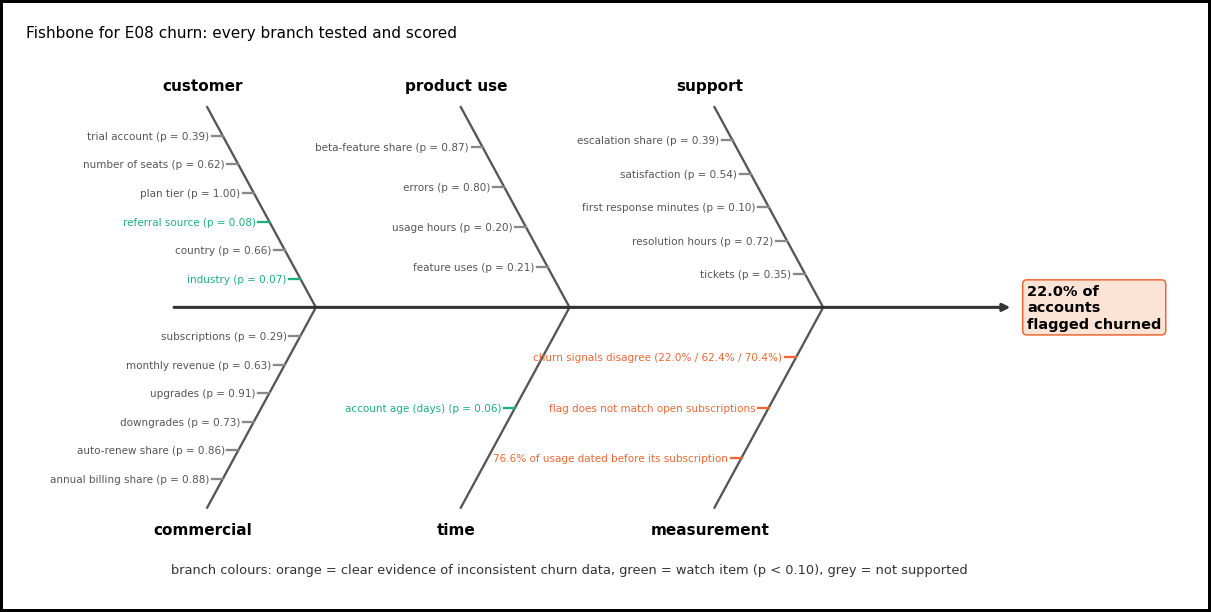

In [6]:
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.annotate("", xy=(9.3, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="#333333", lw=2))
ax.text(9.45, 0, "22.0% of\naccounts\nflagged churned", va="center", ha="left", fontsize=9.5, fontweight="bold",
        bbox=dict(boxstyle="round", fc="#fbe3d6", ec=ORANGE))
color = {"supported": ORANGE, "watch item": AQUA, "not supported": GREY}
layout = [("customer", 1.6, 1), ("product use", 4.4, 1), ("support", 7.2, 1),
          ("commercial", 1.6, -1), ("time", 4.4, -1), ("measurement", 7.2, -1)]
for bone, x, side in layout:
    ax.plot([x - 1.2, x], [2.3 * side, 0], color="#555555", lw=1.5)
    ax.text(x - 1.25, 2.55 * side, bone, ha="center", va="center", fontsize=10, fontweight="bold")
    items = tests[tests["bone"] == bone]
    if bone == "measurement":
        lines = [("churn signals disagree (22.0% / 62.4% / 70.4%)", ORANGE), ("flag does not match open subscriptions", ORANGE),
                 ("76.6% of usage dated before its subscription", ORANGE)]
    else:
        lines = [(f"{r['branch']} (p = {r['p-value']:.2f})", color[r["score"]]) for _, r in items.iterrows()]
    for k, (txt, c) in enumerate(lines):
        frac = (k + 1) / (len(lines) + 1)
        bx, by = x - 1.2 * frac, 2.3 * side * frac
        ax.plot([bx - 0.12, bx], [by, by], color=c, lw=1.5)
        ax.text(bx - 0.15, by, txt, ha="right", va="center", fontsize=6.8, color=c if c != GREY else "#555555")
ax.text(0, -3.05, "branch colours: orange = clear evidence of inconsistent churn data, green = watch item (p < 0.10), grey = not supported", fontsize=8.5, color="#333333")
ax.set_xlim(-1.6, 11.2); ax.set_ylim(-3.2, 3.0); ax.axis("off")
ax.set_title("Fishbone for E08 churn: every branch tested and scored", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

**Observation:** 22 branches were tested. At the usual 5% bar, about 1.1 would look "significant" by chance alone; none did. The corrected bar is 0.0023, and the lowest p-value (0.059, account age) is far above it. Three branches are watch items (p below 0.10, a chosen bar for "worth a second look"): account age, industry and referral source.

**Conclusion:** no customer, product, support, commercial or time branch is a supported cause of churn in this data. The only bone with clear evidence (in the opposite direction, that the churn data is **inconsistent**) is measurement: the churn label is contradicted by the other tables, so it cannot be trusted as it is. That is the honest end of this fishbone, and it is also the most useful finding: fix the label before testing causes again.

**What would settle it:** one agreed definition of churn, with a churn date, joined to each account's usage and support history over the same timeline.

## Exercise — Is industry a driver?

A teammate points at the customer bone: *"DevTools accounts churn at 31.0% and Cybersecurity at 16.0%. Industry has the lowest p-value on the bone. That's our driver."* Is it?

In [7]:
ind = A.groupby("industry")["churn_flag"].agg(["mean", "size", "sum"])
print("Churn by industry:")
for k, r in ind.iterrows():
    print(f"  {k} = {r['sum']:.0f} of {r['size']:.0f} = {r['mean']:.1%}")
p_ind = customer.loc[customer["branch"] == "industry", "p-value"].iloc[0]
print(f"\nindustry p-value = {p_ind:.3f}")
print(f"Bonferroni threshold for {n_tests} branches = {bonf:.4f}")

Churn by industry:
  Cybersecurity = 16 of 100 = 16.0%
  DevTools = 35 of 113 = 31.0%
  EdTech = 13 of 79 = 16.5%
  FinTech = 25 of 112 = 22.3%
  HealthTech = 21 of 96 = 21.9%

industry p-value = 0.066
Bonferroni threshold for 22 branches = 0.0023


**Answer:** no. Four reasons:
1. **It does not pass even the usual bar:** p = 0.066 is above 0.05.
2. **Many branches were tested:** with 22 branches, about 1.1 would look significant by chance alone. The corrected bar is 0.0023, and 0.066 is far above it.
3. **The label it is tested against is unreliable** (Part 4): a gap in "churn flag" rates is a gap in a flag the other tables do not confirm.
4. **Every industry churns:** all 5 do, from 16.0% (Cybersecurity) to 31.0% (DevTools). Even in the best one, about 1 account in 6 churns, so whatever drives churn is present in all of them; industry could at most explain why some churn more.

Industry is a **watch item**: worth checking again once churn is measured properly, not a driver to act on.

## Key takeaways

- **A fishbone lists every candidate cause first,** sorted into bones, so the team tests more than the first idea. Here: six bones, 22 tested branches plus the label checks.
- **Every branch is a hypothesis until tested.** None of the 22 reached p < 0.05; the lowest was 0.059 (account age).
- **Correct for testing many at once.** With 22 tests, about 1.1 false "hits" are expected at the 5% bar; the Bonferroni bar was 0.0023.
- **Always put a measurement bone on the fishbone.** Here it carried the only clear evidence, that the churn data is inconsistent: the three churn signals disagree (22.0%, 62.4%, 70.4%), and every account, flagged or not, still has an open subscription.
- **"No supported branch" is a real result.** The right deliverable is a diagnosis plus a fix to the measurement, not a list of actions on unproven causes.
- **In DMAIC, this is Analyze:** breadth first, then each branch tested.